#credit_default_project

In [ ]:
train_path = "data/train_dataset_final1.csv"
val_path = "data/validate_dataset_final.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 100)

import warnings
warnings.filterwarnings("ignore")

from imblearn.over_sampling import SMOTE
from collections import Counter

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from xgboost import XGBClassifier

from sklearn import metrics
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay

## Data Pre-processing and Data Visualization

In [ ]:
df_train = pd.read_csv(train_path)
df_val = pd.read_csv(val_path)


In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25247 entries, 0 to 25246
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         25247 non-null  int64  
 1   marriage            25247 non-null  int64  
 2   sex                 25247 non-null  int64  
 3   education           25247 non-null  int64  
 4   LIMIT_BAL           25247 non-null  int64  
 5   age                 25121 non-null  float64
 6   pay_0               25247 non-null  int64  
 7   pay_2               25247 non-null  int64  
 8   pay_3               25247 non-null  int64  
 9   pay_4               25247 non-null  int64  
 10  pay_5               25247 non-null  int64  
 11  pay_6               25247 non-null  int64  
 12  Bill_amt1           25247 non-null  float64
 13  Bill_amt2           25247 non-null  float64
 14  Bill_amt3           25247 non-null  float64
 15  Bill_amt4           25247 non-null  float64
 16  Bill

In [ ]:
df_train.isnull().sum()

,0
Customer_ID,0
marriage,0
sex,0
education,0
LIMIT_BAL,0
age,126
pay_0,0
pay_2,0
pay_3,0
pay_4,0


In [ ]:
# Check if missingness correlates with default
print(df_train[df_train['age'].isnull()]['next_month_default'].value_counts(normalize=True))

next_month_default
0    0.81746
1    0.18254
Name: proportion, dtype: float64


In [ ]:
median_age = df_train['age'].median()
df_train['age'].fillna(median_age, inplace=True)


In [ ]:
df_train.isnull().sum()

,0
Customer_ID,0
marriage,0
sex,0
education,0
LIMIT_BAL,0
age,0
pay_0,0
pay_2,0
pay_3,0
pay_4,0


In [ ]:
df_train.describe()

,Customer_ID,marriage,sex,education,LIMIT_BAL,age,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6,Bill_amt1,Bill_amt2,Bill_amt3,Bill_amt4,Bill_amt5,Bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,AVG_Bill_amt,PAY_TO_BILL_ratio,next_month_default
count,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,2.524700e+04,25247.000000,25247.000000,25247.000000,25247.000000,2.524700e+04,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000,25247.000000
mean,17640.000000,1.551907,0.604111,1.852101,168342.060443,35.431022,-0.042857,-0.159544,-0.190359,-0.241415,-0.282568,-0.307680,51170.887938,49092.268745,4.695839e+04,43134.911103,40218.976171,38806.221029,5718.624966,6.047352e+03,5288.910651,4865.960834,4906.766828,5270.499287,44859.647485,0.362962,0.190399
std,7288.325459,0.522629,0.489050,0.797379,129892.784807,9.152635,1.099315,1.173990,1.172636,1.146753,1.114213,1.130864,73250.806650,70695.367650,6.895687e+04,63846.205694,60389.690737,59182.792531,16806.842125,2.400962e+04,17851.879609,15979.116544,15860.726852,17960.816915,62819.226119,5.047206,0.392624
min,5017.000000,0.000000,0.000000,0.000000,10000.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,-56043.170000,-546.930000,0.000000
25%,11328.500000,1.000000,0.000000,1.000000,50000.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3601.340000,3017.155000,2.753275e+03,2319.615000,1770.625000,1241.710000,999.985000,9.219100e+02,399.990000,300.150000,262.365000,130.070000,4858.670000,0.040000,0.000000
50%,17640.000000,2.000000,1.000000,2.000000,140000.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22436.740000,21245.880000,2.008554e+04,19027.840000,18069.760000,17102.580000,2145.020000,2.026830e+03,1844.300000,1500.100000,1513.790000,1500.040000,21102.830000,0.090000,0.000000
75%,23951.500000,2.000000,1.000000,2.000000,240000.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67373.410000,64151.875000,6.022971e+04,54391.160000,50289.525000,49245.195000,5031.150000,5.000190e+03,4600.640000,4014.990000,4099.890000,4018.780000,57136.580000,0.590000,0.000000
max,30263.000000,3.000000,1.000000,6.000000,1000000.000000,79.000000,8.000000,8.000000,8.000000,7.000000,7.000000,8.000000,964511.160000,983931.050000,1.664089e+06,891585.580000,927172.770000,961663.620000,873551.980000,1.684259e+06,896040.150000,621000.080000,426529.180000,528666.150000,877313.830000,205.380000,1.000000


In [ ]:
df_train.sample(10)

,Customer_ID,marriage,sex,education,LIMIT_BAL,age,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6,Bill_amt1,Bill_amt2,Bill_amt3,Bill_amt4,Bill_amt5,Bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,AVG_Bill_amt,PAY_TO_BILL_ratio,next_month_default
2320,7337,1,1,2,150000,35.0,2,2,2,-1,-1,-1,1845.94,5465.97,3659.20,2415.67,5033.16,803.91,3672.18,0.05,2415.02,5032.99,803.28,2531.18,3203.83,0.75,1
11115,16132,1,1,2,500000,40.0,-2,-2,-2,-2,-1,0,240928.69,18675.59,9389.79,0.00,282776.96,288936.89,1092.82,9428.98,3422.85,291227.03,9011.14,9030.16,139489.17,0.39,0
19705,24722,2,1,1,250000,36.0,0,0,0,0,0,0,111204.87,114953.60,116608.66,120564.70,121477.21,124115.00,5600.01,5000.06,5899.76,4399.98,4600.21,5100.10,118153.67,0.04,0
19607,24624,2,1,2,480000,39.0,0,0,0,0,0,0,502903.82,481990.41,476680.53,402695.33,362127.66,347271.32,179999.77,16999.95,12637.97,12058.00,11100.94,9566.61,428944.67,0.09,0
14000,19017,2,1,1,50000,26.0,0,0,0,0,0,0,48339.80,48284.09,40988.03,26695.37,18883.74,20130.93,3007.87,2023.87,3000.13,999.90,5000.26,1500.11,33886.67,0.08,0
10514,15531,2,1,1,330000,26.0,0,0,0,0,0,0,58666.40,38323.47,32725.99,43579.59,28908.20,20777.32,2212.95,4999.69,20000.14,999.97,671.98,1199.95,37163.33,0.13,0
2772,7789,1,0,1,500000,35.0,2,0,0,-1,0,0,510366.97,473584.15,167681.62,501495.41,508212.64,496801.00,24912.69,5871.99,508228.86,18089.29,14069.51,15008.81,443023.83,0.22,1
6578,11595,2,0,2,20000,52.0,0,0,0,2,2,-2,13874.43,14489.10,16028.25,15470.09,0.00,0.00,1237.96,2558.94,0.00,0.00,0.00,0.11,9976.83,0.06,0
2881,7898,1,0,2,20000,45.0,-2,-2,2,2,2,2,0.00,1961.26,2982.20,2790.41,3588.09,3387.07,5965.76,1200.69,0.08,1000.26,0.00,1000.19,2111.17,0.72,0
3487,8504,2,1,2,30000,38.0,1,-2,-2,-1,2,2,0.57,0.00,1.21,240.04,89.39,588.44,0.16,0.09,238.84,0.00,499.86,0.11,152.83,0.81,0


In [ ]:
df_train.drop(["Customer_ID"], axis=1, inplace= True)
df_train.rename(columns={"next_month_default": "default"}, inplace=True)

In [ ]:
df_train.columns

Index(['marriage', 'sex', 'education', 'LIMIT_BAL', 'age', 'pay_0', 'pay_2',
       'pay_3', 'pay_4', 'pay_5', 'pay_6', 'Bill_amt1', 'Bill_amt2',
       'Bill_amt3', 'Bill_amt4', 'Bill_amt5', 'Bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6',
       'AVG_Bill_amt', 'PAY_TO_BILL_ratio', 'default'],
      dtype='object')

In [ ]:
ca=['marriage', 'sex', 'education', 'pay_0', 'pay_2',
       'pay_3', 'pay_4', 'pay_5', 'pay_6',]
for i in ca:
    print (i,df_train[i].unique())


marriage [2 1 3 0]
sex [0 1]
education [2 1 3 4 5 6 0]
pay_0 [ 2  0 -2 -1  1  8  4  3  5  6  7]
pay_2 [ 2  0 -2 -1  7  4  3  1  5  6  8]
pay_3 [ 2 -2  0 -1  6  3  4  1  7  5  8]
pay_4 [ 0 -2 -1  2  5  3  4  7  6  1]
pay_5 [ 0 -1 -2  2  4  3  6  7  5]
pay_6 [ 0 -2 -1  2  3  4  5  7  6  8]


In [ ]:
df_train['education'].replace({0:4,5:4,6:4}, inplace=True)
df_train.education.value_counts()

,count
education,
2,11717
1,8988
3,4115
4,427


In [ ]:
df_train['marriage'].replace({0:3}, inplace=True)
df_train.marriage.value_counts()

,count
marriage,
2,13441
1,11480
3,326


##Data Visualization OR EDA


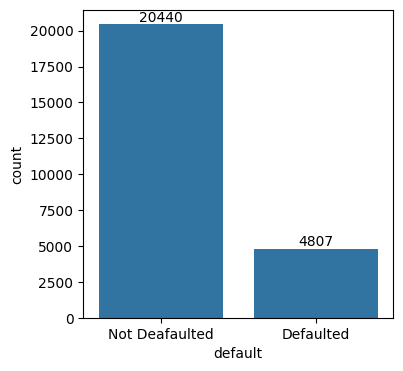

In [ ]:
plt.figure(figsize=(4,4))
ax=sns.countplot(x= df_train['default'])
for label in ax.containers:
    ax.bar_label(label)
plt.xticks([0,1], labels=["Not Deafaulted", "Defaulted"])
plt.show()

**Results from Default Distribution Plot:**
This plot shows the distribution of the target variable 'default'. It indicates the number of customers who defaulted in the next month (labeled as 1) and those who did not (labeled as 0). This helps understand the class imbalance in the dataset.

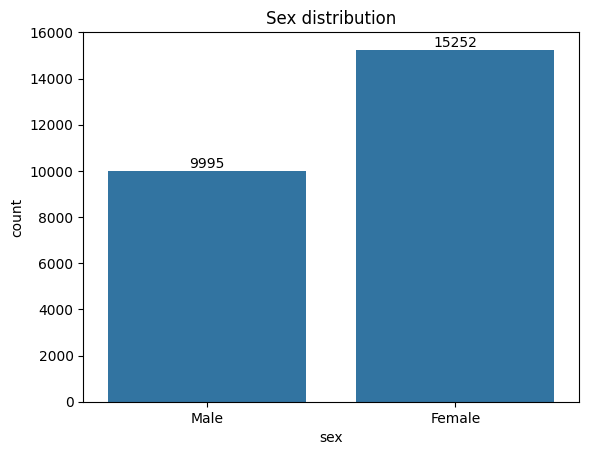

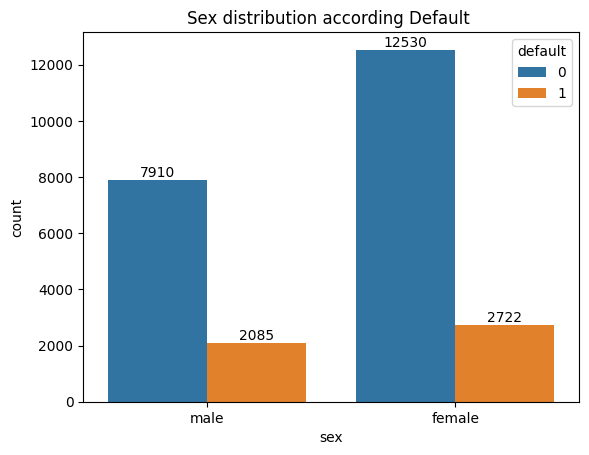

In [ ]:
ax=sns.countplot(x= df_train['sex'])
for label in ax.containers:
    ax.bar_label(label)
plt.xticks([0,1], labels=["Male", "Female"])
plt.title("Sex distribution")
plt.show()

ax=sns.countplot(data=df_train, x="sex", hue="default")
for label in ax.containers:
    ax.bar_label(label)
plt.xticks([0,1], labels=["male", "female"])
plt.title("Sex distribution according Default ")
plt.show()

**Results from Sex Distribution Plots:**
The first plot shows the overall distribution of sex in the dataset, indicating the number of male and female customers. The second plot breaks down the sex distribution by default status, allowing us to see if there's a difference in the default rate between male and female customers.

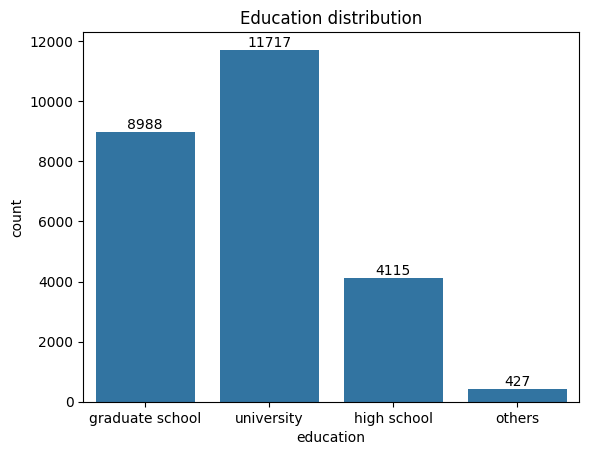

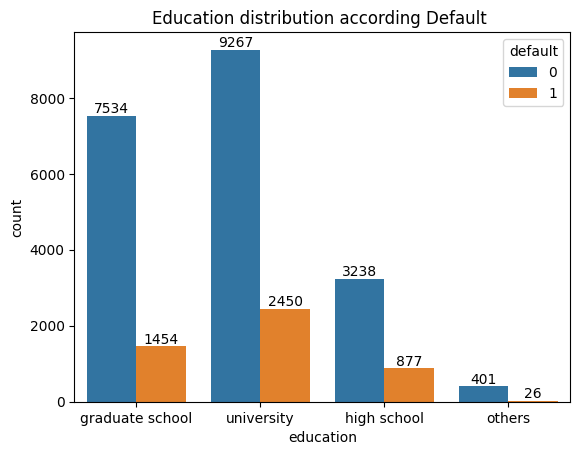

In [ ]:
ax=sns.countplot(x= df_train['education'])
for label in ax.containers:
    ax.bar_label(label)
plt.xticks([0,1,2,3], labels=["graduate school", "university",'high school','others'])
plt.title("Education distribution")
plt.show()

ax=sns.countplot(data=df_train, x="education", hue="default")
for label in ax.containers:
    ax.bar_label(label)
plt.xticks([0,1,2,3], labels=["graduate school", "university",'high school','others'])
plt.title("Education distribution according Default ")
plt.show()

**Results from Education Distribution Plots:**
The first plot shows the overall distribution of education levels among the customers. The second plot shows the education distribution according to default status, which helps in understanding if certain education levels are more prone to defaulting.

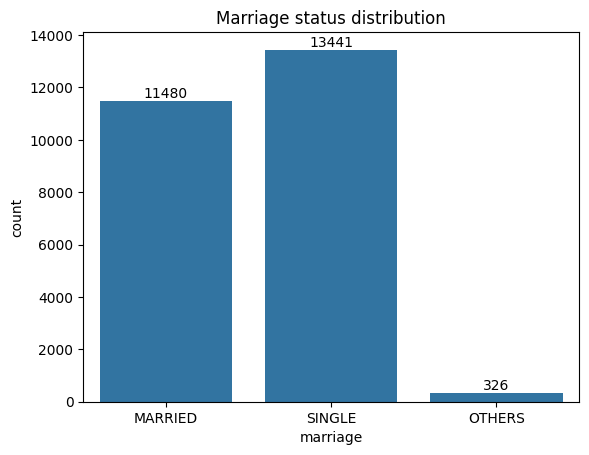

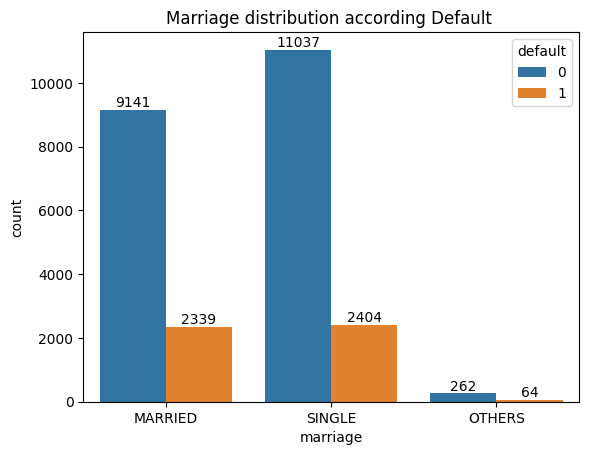

In [ ]:
ax=sns.countplot(x= df_train['marriage'])
for label in ax.containers:
    ax.bar_label(label)
plt.xticks([0,1,2], labels=["MARRIED", "SINGLE",'OTHERS'])
plt.title("Marriage status distribution")
plt.show()

ax=sns.countplot(data=df_train, x="marriage", hue="default")
for label in ax.containers:
    ax.bar_label(label)
plt.xticks([0,1,2], labels=["MARRIED", "SINGLE",'OTHERS'])
plt.title("Marriage distribution according Default ")
plt.show()

**Results from Marriage Status Distribution Plots:**
The first plot displays the distribution of marriage statuses (MARRIED, SINGLE, OTHERS) in the dataset. The second plot shows the marriage status distribution based on default status, allowing for an analysis of whether marriage status influences the likelihood of default.

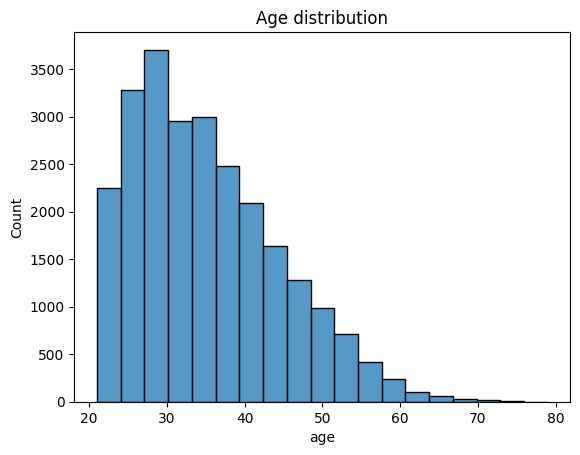

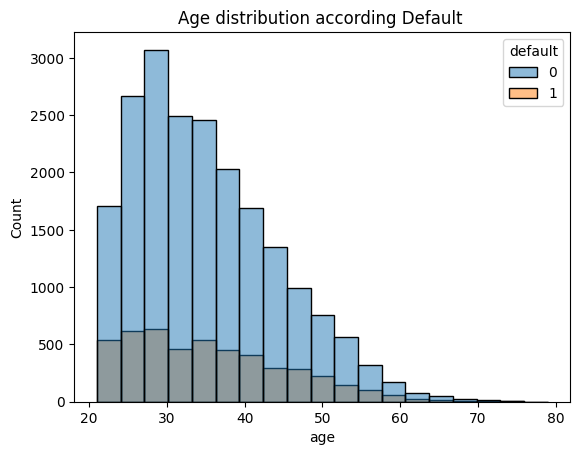

In [ ]:
sns.histplot(data=df_train, x="age",binwidth=3)
plt.title("Age distribution")
plt.show()

sns.histplot(data=df_train, x="age", hue="default", binwidth=3)
plt.title("Age distribution according Default ")
plt.show()

**Results from Age Distribution Plots:**
The first histogram shows the overall distribution of age among the customers. The second histogram shows the age distribution separated by default status, which helps to identify if certain age groups have a higher or lower default rate.

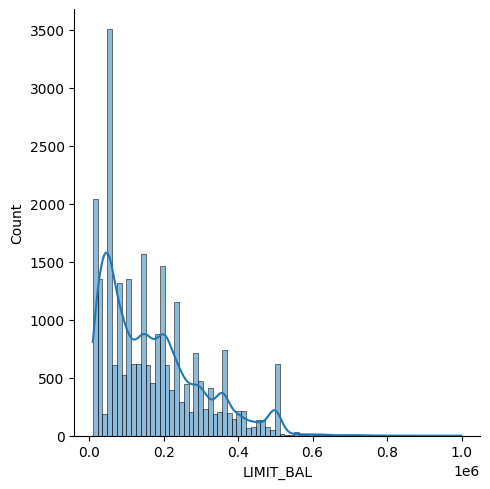

In [ ]:
sns.displot(df_train.LIMIT_BAL, kde=True)

**Results from LIMIT_BAL Distribution Plot:**
This distribution plot shows the distribution of the credit limit (LIMIT_BAL) among the customers. It helps to understand the range and frequency of different credit limits in the dataset.

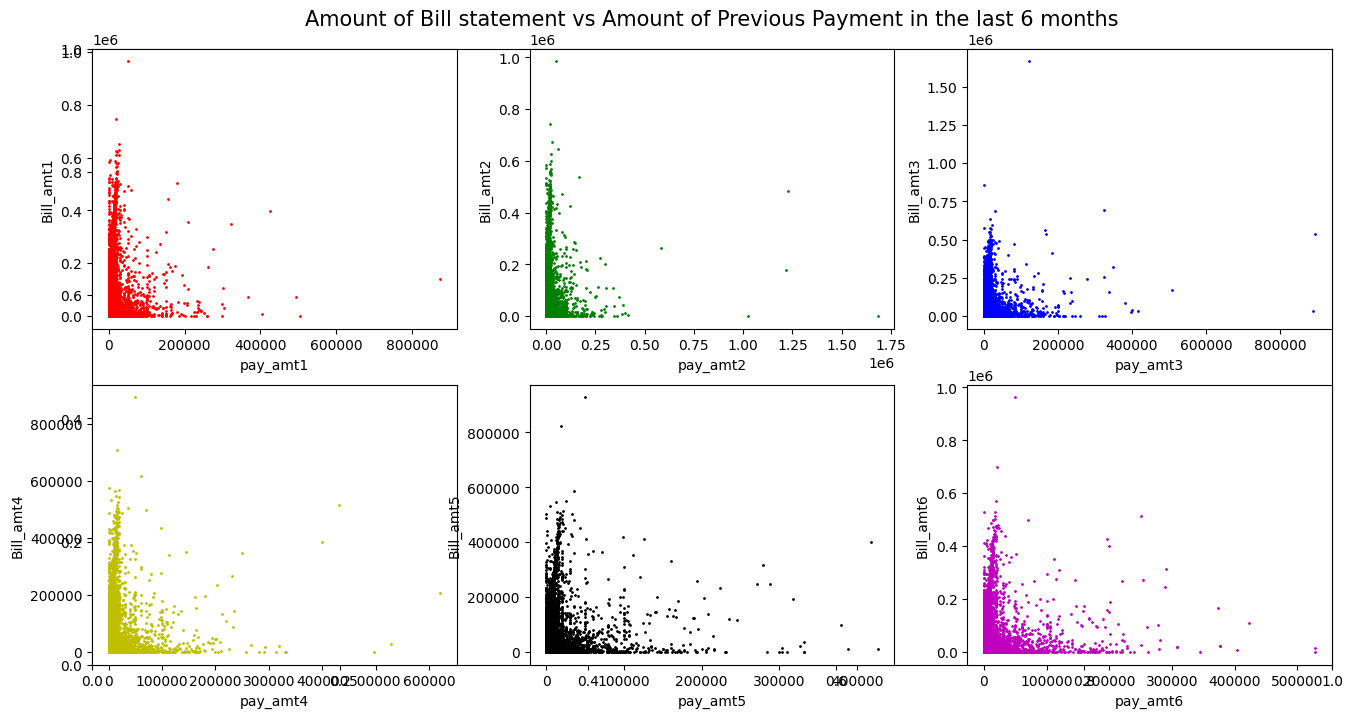

In [ ]:
plt.subplots(figsize=(16,8))
plt.subplot(231)
plt.scatter(x=df_train.pay_amt1, y=df_train.Bill_amt1, c='r', s=1)
plt.xlabel('pay_amt1')
plt.ylabel('Bill_amt1')

plt.subplot(232)
plt.scatter(x=df_train.pay_amt2, y=df_train.Bill_amt2, c='g', s=1)
plt.xlabel('pay_amt2')
plt.ylabel('Bill_amt2')
plt.title('Amount of Bill statement vs Amount of Previous Payment in the last 6 months', fontsize=15)

plt.subplot(233)
plt.scatter(x=df_train.pay_amt3, y=df_train.Bill_amt3, c='b', s=1)
plt.xlabel('pay_amt3')
plt.ylabel('Bill_amt3')

plt.subplot(234)
plt.scatter(x=df_train.pay_amt4, y=df_train.Bill_amt4, c='y', s=1)
plt.xlabel('pay_amt4')
plt.ylabel('Bill_amt4')

plt.subplot(235)
plt.scatter(x=df_train.pay_amt5, y=df_train.Bill_amt5, c='black', s=1)
plt.xlabel('pay_amt5')
plt.ylabel('Bill_amt5')

plt.subplot(236)
plt.scatter(x=df_train.pay_amt6, y=df_train.Bill_amt6, c='m', s=1)
plt.xlabel('pay_amt6')
plt.ylabel('Bill_amt6')


plt.show()

**Results from Bill Amount vs. Payment Amount Scatter Plots:**
These scatter plots visualize the relationship between the bill statement amount and the previous payment amount for each of the past six months. Each subplot represents a different month. These plots can reveal patterns such as whether higher bill amounts are associated with higher payment amounts, or if there are clusters of customers with high bills and low payments, which might indicate a higher risk of default.

<Axes: >

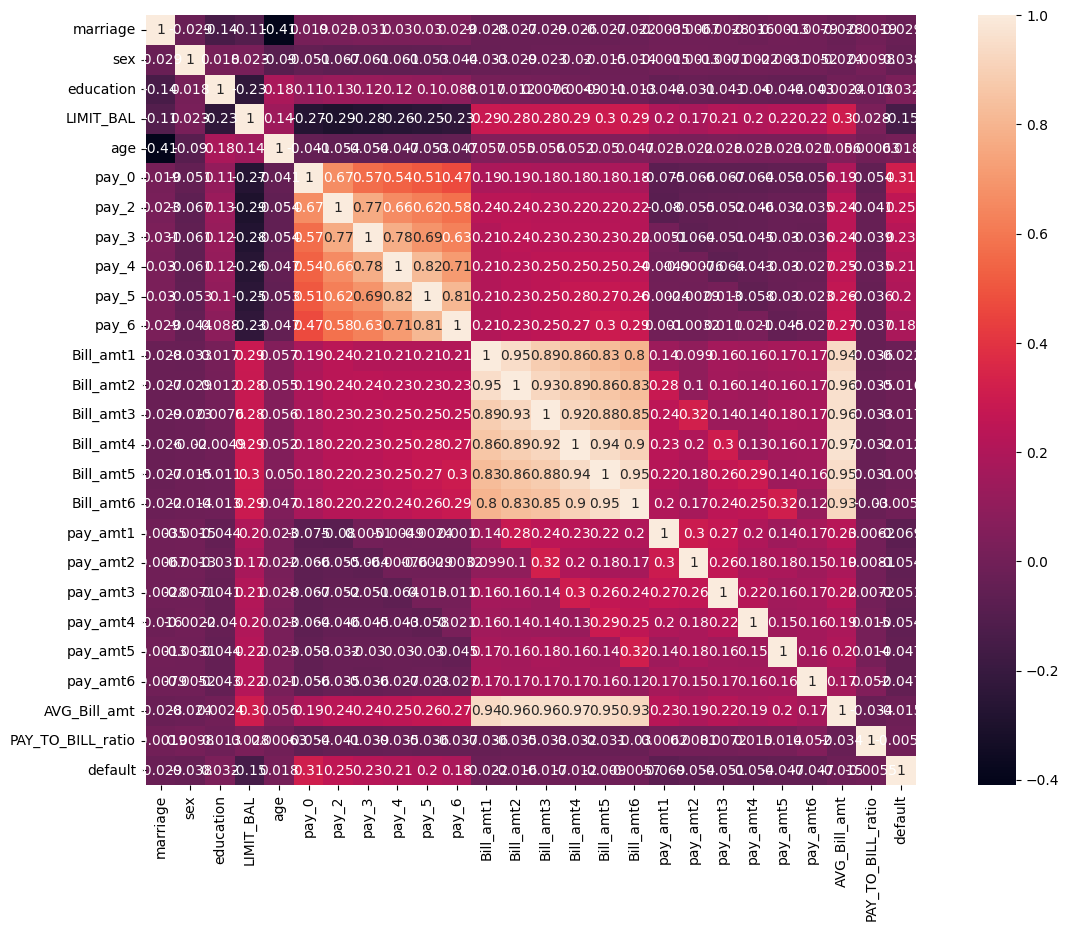

In [ ]:
plt.figure(figsize = (16,10))
sns.heatmap(df_train.corr(),annot = True,square = True)

##Financial Analysis

####Payment-to-Bill Ratio Trend Analysis

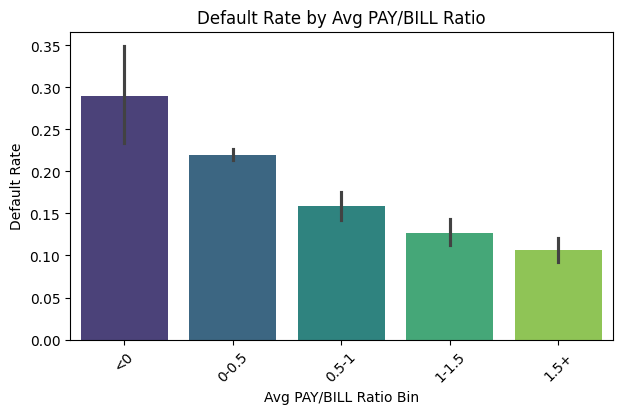

In [ ]:
# Payment to bill ratio per month
for i in range(1, 7):
    df_train[f'pay_bill_ratio_{i}'] = df_train[f'pay_amt{i}'] / df_train[f'Bill_amt{i}'].replace(0, np.nan) #division by 0 causes null values

# Aggregate ratio stats
df_train['avg_pay_bill_ratio'] = df_train[[f'pay_bill_ratio_{i}' for i in range(1, 7)]].mean(axis=1)
df_train['std_pay_bill_ratio'] = df_train[[f'pay_bill_ratio_{i}' for i in range(1, 7)]].std(axis=1)

# Bin and plot average ratio
df_train['ratio_bin'] = pd.cut(df_train['avg_pay_bill_ratio'], bins=[-1, 0, 0.5, 1, 1.5, 3], labels=['<0', '0-0.5', '0.5-1', '1-1.5', '1.5+'])

plt.figure(figsize=(7, 4))
sns.barplot(x='ratio_bin', y='default', data=df_train, palette='viridis')
plt.title('Default Rate by Avg PAY/BILL Ratio')
plt.xticks(rotation=45)
plt.xlabel('Avg PAY/BILL Ratio Bin')
plt.ylabel('Default Rate')
plt.show()

#droping coloumns that might contain null values
df_train.drop(columns=['pay_bill_ratio_1','pay_bill_ratio_2','pay_bill_ratio_3','pay_bill_ratio_4','pay_bill_ratio_5','pay_bill_ratio_6','ratio_bin','avg_pay_bill_ratio','std_pay_bill_ratio'], inplace=True)

**Results from Default Rate by Avg PAY/BILL Ratio Plot:**
This bar plot shows the default rate for different bins of the average payment-to-bill ratio. It helps to understand if customers with a lower average payment-to-bill ratio (meaning they pay back a smaller proportion of their bill amount on average) have a higher default rate.

####Applying the concept of credit utilization

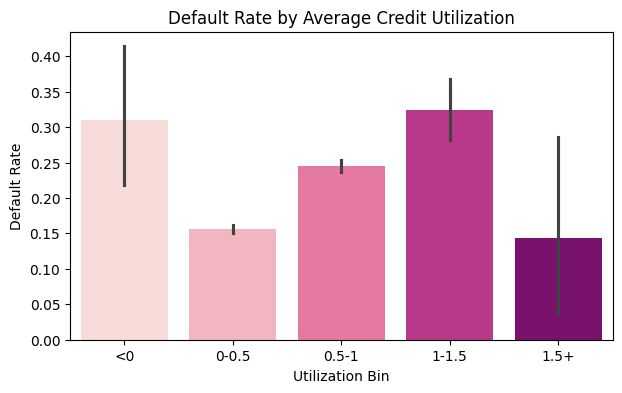

In [ ]:
# Calculate monthly credit utilization
for i in range(1, 7):
    df_train[f'util_{i}'] = df_train[f'Bill_amt{i}'] / df_train['LIMIT_BAL']

# Average and std dev of utilization over 6 months
df_train['avg_util'] = df_train[[f'util_{i}' for i in range(1, 7)]].mean(axis=1)
df_train['std_util'] = df_train[[f'util_{i}' for i in range(1, 7)]].std(axis=1)

# Binning utilization
df_train['util_bin'] = pd.cut(df_train['avg_util'], bins=[-1, 0, 0.5, 1, 1.5, 3], labels=['<0', '0-0.5', '0.5-1', '1-1.5', '1.5+'])

# Plot
plt.figure(figsize=(7, 4))
sns.barplot(x='util_bin', y='default', data=df_train, palette='RdPu')
plt.title('Default Rate by Average Credit Utilization')
plt.ylabel('Default Rate')
plt.xlabel('Utilization Bin')
plt.show()

**Results from Default Rate by Average Credit Utilization Plot:**
This bar plot shows the default rate for different bins of average credit utilization. It helps to understand if customers with higher average credit utilization (meaning they are using a larger proportion of their available credit) have a higher default rate. The plot visually indicates how default risk changes with different levels of credit utilization.

##Modelling

In [ ]:
X = df_train.drop(['default'], axis=1)

y = df_train['default']
X.head()

,marriage,sex,education,LIMIT_BAL,age,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6,Bill_amt1,Bill_amt2,Bill_amt3,Bill_amt4,Bill_amt5,Bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,AVG_Bill_amt,PAY_TO_BILL_ratio
0,2,0,2,60000,25.0,2,2,2,0,0,0,60323.86,60728.22,56472.74,28602.01,22191.53,20750.63,2000.21,0.00,1134.85,1821.78,1500.03,1500.24,41511.50,0.03
1,2,1,1,290000,24.0,0,0,-2,-2,-1,0,11157.67,0.00,0.88,0.65,2700.96,1350.30,0.00,0.17,0.00,2700.10,0.00,1349.72,2534.50,0.27
2,1,0,2,180000,63.0,0,0,0,0,0,0,47930.96,48921.91,50034.26,50748.90,51902.56,52991.51,2086.94,2199.99,1845.66,2000.35,1923.00,1999.78,50422.00,0.04
3,1,1,2,210000,43.0,0,0,0,0,0,0,91152.44,92916.01,90652.30,85295.56,80416.75,76945.47,3348.07,3380.91,3400.45,2683.97,2744.00,2892.10,86229.50,0.04
4,2,0,1,280000,32.0,-2,-2,-2,-2,-2,-2,19666.40,999.04,3186.48,44932.48,2099.77,1.35,999.78,3186.27,45027.78,2100.09,0.01,0.27,11814.33,0.72


### Feature Engineering

In [ ]:
scaler= StandardScaler()
X= scaler.fit_transform(X)

In [ ]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.20,random_state=42)


###SMOTE


In [ ]:
print("Before oversampling: ",Counter(y_train))
SMOTE= SMOTE()

X_train,y_train= SMOTE.fit_resample(X_train,y_train)

print("After oversampling: ",Counter(y_train))

Before oversampling:  Counter({0: 16345, 1: 3852})
After oversampling:  Counter({1: 16345, 0: 16345})


###Logistic Regression

Threshold = 0.25 → F2 Score = 0.5525
Threshold = 0.26 → F2 Score = 0.5532
Threshold = 0.27 → F2 Score = 0.5521
Threshold = 0.28 → F2 Score = 0.5527
Threshold = 0.29 → F2 Score = 0.5532
Threshold = 0.30 → F2 Score = 0.5543
Threshold = 0.31 → F2 Score = 0.5540
Threshold = 0.32 → F2 Score = 0.5558
Threshold = 0.33 → F2 Score = 0.5565
Threshold = 0.34 → F2 Score = 0.5599
Threshold = 0.35 → F2 Score = 0.5596
Threshold = 0.36 → F2 Score = 0.5591
Threshold = 0.37 → F2 Score = 0.5572
Threshold = 0.38 → F2 Score = 0.5530
Threshold = 0.39 → F2 Score = 0.5505
Threshold = 0.40 → F2 Score = 0.5471
Threshold = 0.41 → F2 Score = 0.5493
Threshold = 0.42 → F2 Score = 0.5501
Threshold = 0.43 → F2 Score = 0.5516
Threshold = 0.44 → F2 Score = 0.5500
Threshold = 0.45 → F2 Score = 0.5473
Threshold = 0.46 → F2 Score = 0.5461
Threshold = 0.47 → F2 Score = 0.5519
Threshold = 0.48 → F2 Score = 0.5516
Threshold = 0.49 → F2 Score = 0.5541

✅ Best Threshold = 0.34
🎯 Max F2 Score = 0.5599
Accuracy: 0.41881188118811

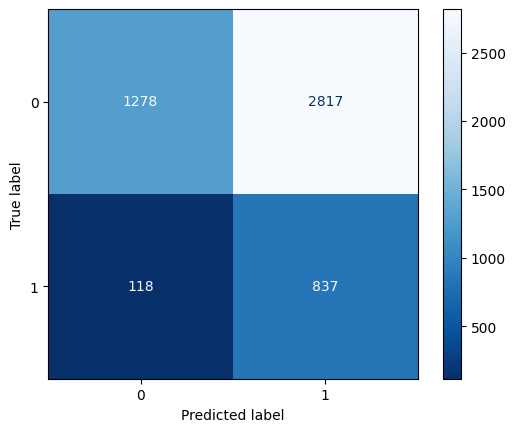

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    fbeta_score
)

# Train the logistic regression model
logit = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logit.fit(X_train, y_train)

# Predict probabilities for the positive class (1)
probs_logit = logit.predict_proba(X_test)[:, 1]

# Threshold search range
thresholds = np.arange(0.25, 0.5, 0.01)

best_f2 = 0
best_threshold = 0.5
best_preds = None

# Loop through thresholds to find best F2 score
for t in thresholds:
    preds = (probs_logit >= t).astype(int)
    f2 = fbeta_score(y_test, preds, beta=2)
    print(f"Threshold = {t:.2f} → F2 Score = {f2:.4f}")

    if f2 > best_f2:
        best_f2 = f2
        best_threshold = t
        best_preds = preds

# Final model evaluation
print(f"\n✅ Best Threshold = {best_threshold:.2f}")
print(f"🎯 Max F2 Score = {best_f2:.4f}")
print("Accuracy:", accuracy_score(y_test, best_preds))
print(classification_report(y_test, best_preds))

# Confusion Matrix
print("Confusion Matrix of Logistic Regression (Threshold Optimized):")
ConfusionMatrixDisplay.from_predictions(y_test, best_preds, cmap="Blues_r")


###Decision Tree

Threshold = 0.30 → F2 Score = 0.5686
Threshold = 0.31 → F2 Score = 0.5707
Threshold = 0.32 → F2 Score = 0.5707
Threshold = 0.33 → F2 Score = 0.5694
Threshold = 0.34 → F2 Score = 0.5696
Threshold = 0.35 → F2 Score = 0.5696
Threshold = 0.36 → F2 Score = 0.5668
Threshold = 0.37 → F2 Score = 0.5592
Threshold = 0.38 → F2 Score = 0.5585
Threshold = 0.39 → F2 Score = 0.5558
Threshold = 0.40 → F2 Score = 0.5539
Threshold = 0.41 → F2 Score = 0.5531
Threshold = 0.42 → F2 Score = 0.5531
Threshold = 0.43 → F2 Score = 0.5477
Threshold = 0.44 → F2 Score = 0.5471
Threshold = 0.45 → F2 Score = 0.5471

✅ Best Threshold = 0.31
🎯 Max F2 Score = 0.5707
Accuracy: 0.578019801980198
              precision    recall  f1-score   support

           0       0.91      0.53      0.67      4095
           1       0.28      0.77      0.41       955

    accuracy                           0.58      5050
   macro avg       0.59      0.65      0.54      5050
weighted avg       0.79      0.58      0.62      5050



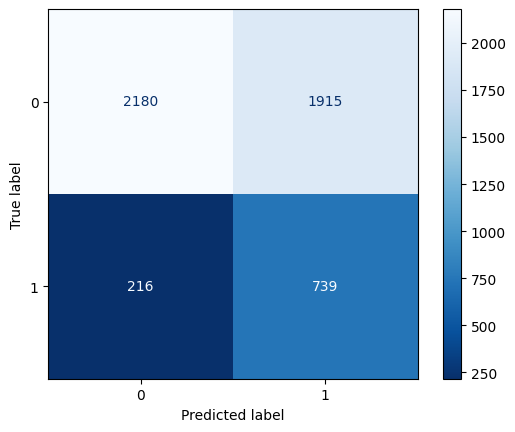

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    fbeta_score
)

# Train Decision Tree
Tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=7,
    max_features=9,
    min_samples_leaf=2,
    random_state=0
)
Tree.fit(X_train, y_train)

# Predict probabilities
probs_tree = Tree.predict_proba(X_test)[:, 1]

# Threshold loop
thresholds = np.arange(0.3, 0.45, 0.01)

best_f2 = 0
best_threshold = 0.5
best_preds = None

for t in thresholds:
    preds = (probs_tree >= t).astype(int)
    f2 = fbeta_score(y_test, preds, beta=2)
    print(f"Threshold = {t:.2f} → F2 Score = {f2:.4f}")

    if f2 > best_f2:
        best_f2 = f2
        best_threshold = t
        best_preds = preds

# Final output
print(f"\n✅ Best Threshold = {best_threshold:.2f}")
print(f"🎯 Max F2 Score = {best_f2:.4f}")
print("Accuracy:", accuracy_score(y_test, best_preds))
print(classification_report(y_test, best_preds))
ConfusionMatrixDisplay.from_predictions(y_test, best_preds, cmap="Blues_r")


###Random Forest

Threshold = 0.22 → F2 Score = 0.6023
Threshold = 0.23 → F2 Score = 0.6001
Threshold = 0.24 → F2 Score = 0.5916
Threshold = 0.25 → F2 Score = 0.5916
Threshold = 0.26 → F2 Score = 0.5902
Threshold = 0.27 → F2 Score = 0.5925
Threshold = 0.28 → F2 Score = 0.5902
Threshold = 0.29 → F2 Score = 0.5853
Threshold = 0.30 → F2 Score = 0.5797
Threshold = 0.31 → F2 Score = 0.5830
Threshold = 0.32 → F2 Score = 0.5832
Threshold = 0.33 → F2 Score = 0.5811
Threshold = 0.34 → F2 Score = 0.5739

✅ Best Threshold = 0.22
🎯 Max F2 Score = 0.6023
Accuracy: 0.5603960396039604
              precision    recall  f1-score   support

           0       0.93      0.49      0.65      4095
           1       0.28      0.85      0.42       955

    accuracy                           0.56      5050
   macro avg       0.61      0.67      0.53      5050
weighted avg       0.81      0.56      0.60      5050



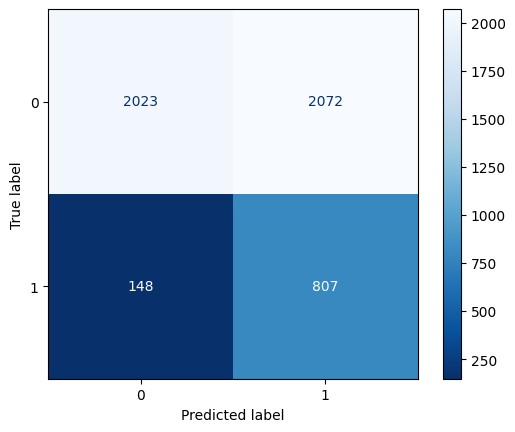

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    fbeta_score
)

# Train Random Forest
rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

# Predict probabilities
probs_rf = rf.predict_proba(X_test)[:, 1]

# Threshold loop
thresholds = np.arange(0.22, 0.35, 0.01)

best_f2 = 0
best_threshold = 0.5
best_preds = None

for t in thresholds:
    preds = (probs_rf >= t).astype(int)
    f2 = fbeta_score(y_test, preds, beta=2)
    print(f"Threshold = {t:.2f} → F2 Score = {f2:.4f}")

    if f2 > best_f2:
        best_f2 = f2
        best_threshold = t
        best_preds = preds

# Final output
print(f"\n✅ Best Threshold = {best_threshold:.2f}")
print(f"🎯 Max F2 Score = {best_f2:.4f}")
print("Accuracy:", accuracy_score(y_test, best_preds))
print(classification_report(y_test, best_preds))
ConfusionMatrixDisplay.from_predictions(y_test, best_preds, cmap="Blues_r")


###XGBOOST

Threshold = 0.10 → F2 Score = 0.5837
Threshold = 0.11 → F2 Score = 0.5858
Threshold = 0.12 → F2 Score = 0.5832
Threshold = 0.13 → F2 Score = 0.5850
Threshold = 0.14 → F2 Score = 0.5816
Threshold = 0.15 → F2 Score = 0.5814
Threshold = 0.16 → F2 Score = 0.5794
Threshold = 0.17 → F2 Score = 0.5774
Threshold = 0.18 → F2 Score = 0.5764
Threshold = 0.19 → F2 Score = 0.5732
Threshold = 0.20 → F2 Score = 0.5698
Threshold = 0.21 → F2 Score = 0.5658
Threshold = 0.22 → F2 Score = 0.5624
Threshold = 0.23 → F2 Score = 0.5565
Threshold = 0.24 → F2 Score = 0.5457

✅ Best Threshold = 0.11
🎯 Max F2 Score = 0.5858
Accuracy: 0.519009900990099
              precision    recall  f1-score   support

           0       0.93      0.44      0.60      4095
           1       0.26      0.85      0.40       955

    accuracy                           0.52      5050
   macro avg       0.59      0.65      0.50      5050
weighted avg       0.80      0.52      0.56      5050

Confusion Matrix of XGBoost (Threshold Op

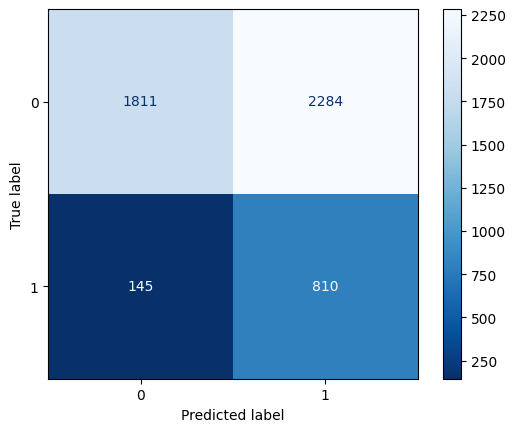

In [ ]:
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    fbeta_score
)

# Train XGBoost
xgboost = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgboost.fit(X_train, y_train)

# Predict probabilities for the positive class
probs_xgb = xgboost.predict_proba(X_test)[:, 1]

# Try different thresholds to find the best F2 score
thresholds = np.arange(0.1, 0.25, 0.01)

best_f2 = 0
best_threshold = 0.5
best_preds = None

for t in thresholds:
    preds = (probs_xgb >= t).astype(int)
    f2 = fbeta_score(y_test, preds, beta=2)
    print(f"Threshold = {t:.2f} → F2 Score = {f2:.4f}")

    if f2 > best_f2:
        best_f2 = f2
        best_threshold = t
        best_preds = preds

# Final Evaluation
print(f"\n✅ Best Threshold = {best_threshold:.2f}")
print(f"🎯 Max F2 Score = {best_f2:.4f}")
print("Accuracy:", accuracy_score(y_test, best_preds))
print(classification_report(y_test, best_preds))

# Confusion Matrix
print("Confusion Matrix of XGBoost (Threshold Optimized):")
ConfusionMatrixDisplay.from_predictions(y_test, best_preds, cmap="Blues_r")


####Hypertuning

In [ ]:
params={
 "learning_rate"    : [0.05, 0.10, 0.15, 0.20, 0.25, 0.30 ] ,
 "max_depth"        : [ 3, 4, 5, 6, 8, 10, 12, 15],
 "min_child_weight" : [ 1, 3, 5, 7 ],
 "gamma"            : [ 0.0, 0.1, 0.2 , 0.3, 0.4 ],
 "colsample_bytree" : [ 0.3, 0.4, 0.5 , 0.7 ]
}

In [ ]:
random_search=RandomizedSearchCV(xgboost,param_distributions=params,n_iter=5,scoring='roc_auc',n_jobs=-1,cv=5,verbose=3)

random_search.fit(X_train,y_train)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='logloss',
                                           feature_types=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraints=None,
                                           learning...
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None,
                                           random_state=42, ...),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.3, 0.4, 0.5,
                                                             0.7],
                                        'gamma': [0.0, 0.1, 0.2, 0.3, 0.4],
                                        'learning_rate': [0.05, 0.1, 0.15, 0.2,
                                                          0.25, 0.3],
                                        'max_depth': [3, 4, 5, 6, 8, 10, 12,
                                                      15],
                                        'min_child_weight': [1, 3, 5, 7]},
                   scoring='roc_auc', verbose=3)

In [ ]:
random_search.best_estimator_

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.3, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=0.1, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.3, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=15,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

In [ ]:
random_search.best_params_

{'min_child_weight': 1,
 'max_depth': 15,
 'learning_rate': 0.3,
 'gamma': 0.1,
 'colsample_bytree': 0.3}

In [ ]:
classifier=XGBClassifier(objective='binary:logistic',
                                  min_child_weight=3,
                                  max_depth=10,
                                  learning_rate=0.25,
                                  gamma=0.1,
                                  colsample_bynode=1,
                                  colsample_bytree=0.4,
                                  use_label_encoder=False)

# Fitting the model
classifier.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=1, colsample_bytree=0.4,
              device=None, early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=0.1, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.25, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=10,
              max_leaves=None, min_child_weight=3, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

Threshold = 0.00 → F2 Score = 0.5383
Threshold = 0.01 → F2 Score = 0.5457
Threshold = 0.02 → F2 Score = 0.5575
Threshold = 0.03 → F2 Score = 0.5668
Threshold = 0.04 → F2 Score = 0.5701
Threshold = 0.05 → F2 Score = 0.5733
Threshold = 0.06 → F2 Score = 0.5818
Threshold = 0.07 → F2 Score = 0.5871
Threshold = 0.08 → F2 Score = 0.5920
Threshold = 0.09 → F2 Score = 0.5959
Threshold = 0.10 → F2 Score = 0.5945
Threshold = 0.11 → F2 Score = 0.5934
Threshold = 0.12 → F2 Score = 0.5954
Threshold = 0.13 → F2 Score = 0.5937
Threshold = 0.14 → F2 Score = 0.5919
Threshold = 0.15 → F2 Score = 0.5876
Threshold = 0.16 → F2 Score = 0.5842
Threshold = 0.17 → F2 Score = 0.5769
Threshold = 0.18 → F2 Score = 0.5725
Threshold = 0.19 → F2 Score = 0.5694

✅ Best Threshold = 0.09
🎯 Max F2 Score = 0.5959
Accuracy: 0.5611881188118812
              precision    recall  f1-score   support

           0       0.93      0.50      0.65      4095
           1       0.28      0.83      0.42       955

    accuracy      

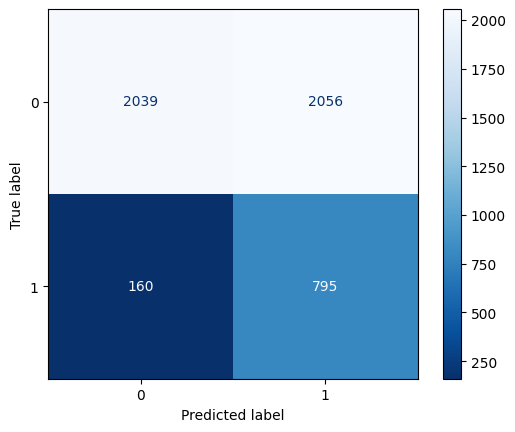

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, fbeta_score, ConfusionMatrixDisplay
import numpy as np

# Get predicted probabilities from the hyperparameter-tuned model
hyper_probs = classifier.predict_proba(X_test)[:, 1]

# Search for the best threshold
thresholds = np.arange(0.0, 0.2, 0.01)

best_f2 = 0
best_threshold = 0.5
best_preds = None

for t in thresholds:
    preds = (hyper_probs >= t).astype(int)
    f2 = fbeta_score(y_test, preds, beta=2)
    print(f"Threshold = {t:.2f} → F2 Score = {f2:.4f}")

    if f2 > best_f2:
        best_f2 = f2
        best_threshold = t
        best_preds = preds

# Final evaluation using best threshold
print(f"\n✅ Best Threshold = {best_threshold:.2f}")
print(f"🎯 Max F2 Score = {best_f2:.4f}")
print("Accuracy:", accuracy_score(y_test, best_preds))
print(classification_report(y_test, best_preds))

# Confusion Matrix
print("Confusion Matrix of Hyperparameter-Tuned Model (Threshold Optimized):")
ConfusionMatrixDisplay.from_predictions(y_test, best_preds, cmap="Blues_r")


###ROC

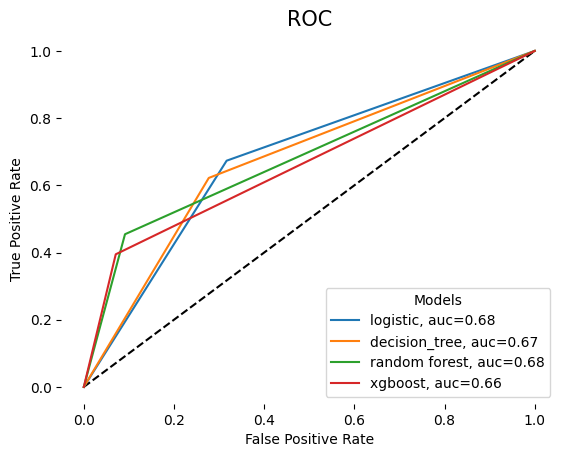

In [ ]:
# logistic model
pred_logit= logit.predict(X_test)
fpr1, tpr1, _ = metrics.roc_curve(y_test,  pred_logit)
auc1 = metrics.roc_auc_score(y_test, pred_logit)

# decision tree model:
pred_tree = Tree.predict(X_test)
fpr2, tpr2, _ = metrics.roc_curve(y_test,  pred_tree)
auc2 = metrics.roc_auc_score(y_test, pred_tree)

# random forest model:
pred_rf= rf.predict(X_test)
fpr3, tpr3, _ = metrics.roc_curve(y_test,  pred_rf)
auc3 = metrics.roc_auc_score(y_test, pred_rf)

# XGboost:
xgboost_pred= xgboost.predict(X_test)
fpr4, tpr4, _ = metrics.roc_curve(y_test,  xgboost_pred)
auc4 = metrics.roc_auc_score(y_test, xgboost_pred)

plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr1,tpr1,label="logistic, auc="+str(round(auc1,2)))
plt.plot(fpr2,tpr2,label="decision_tree, auc="+str(round(auc2,2)))
plt.plot(fpr3,tpr3,label="random forest, auc="+str(round(auc3,2)))
plt.plot(fpr4,tpr4,label="xgboost, auc="+str(round(auc4,2)))

plt.legend(loc=4, title='Models', facecolor='white')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC', size=15)
plt.box(False)
plt.show()

In [ ]:
# Drop the 'Customer_ID' column
df_val.drop(["Customer_ID"], axis=1, inplace= True)

# Fill missing 'age' with the median age from the training data
df_val['age'].fillna(median_age, inplace=True)

# Replace values in 'education'
df_val['education'].replace({0:4,5:4,6:4}, inplace=True)

# Replace values in 'marriage'
df_val['marriage'].replace({0:3}, inplace=True)

KeyError: "['Customer_ID'] not found in axis"

In [ ]:
# Reload the validation dataset
df_val = pd.read_csv(val_path)

In [ ]:
# Save Customer_ID for submission
val_customer_ids = df_val['Customer_ID']

# Drop the 'Customer_ID' column from the validation features
df_val.drop(["Customer_ID"], axis=1, inplace= True)

In [ ]:
# Apply the same preprocessing steps to df_val as df_train

# Fill missing 'age' with the median age from the training data
df_val['age'].fillna(median_age, inplace=True)

# Replace values in 'education'
df_val['education'].replace({0:4,5:4,6:4}, inplace=True)

# Replace values in 'marriage'
df_val['marriage'].replace({0:3}, inplace=True)

# Check for any remaining missing values
print("Missing values in df_val after preprocessing:")
print(df_val.isnull().sum())

Missing values in df_val after preprocessing:
marriage             0
sex                  0
education            0
LIMIT_BAL            0
age                  0
pay_0                0
pay_2                0
pay_3                0
pay_4                0
pay_5                0
pay_6                0
Bill_amt1            0
Bill_amt2            0
Bill_amt3            0
Bill_amt4            0
Bill_amt5            0
Bill_amt6            0
pay_amt1             0
pay_amt2             0
pay_amt3             0
pay_amt4             0
pay_amt5             0
pay_amt6             0
AVG_Bill_amt         0
PAY_TO_BILL_ratio    0
dtype: int64


In [ ]:
# Scale the features of df_val using the scaler fitted on the training data
X_val_scaled = scaler.transform(df_val)

# Use the trained Random Forest model (rf) to predict probabilities
rf_probs_val = rf.predict_proba(X_val_scaled)[:, 1]

# Apply the threshold of 0.23 to get the final predictions
best_threshold_rf = 0.23
rf_val_pred = (rf_probs_val >= best_threshold_rf).astype(int)

# Display the first few predictions
print("First 10 predicted default values for df_val:")
print(rf_val_pred[:10])

First 10 predicted default values for df_val:
[0 0 0 1 0 0 0 0 0 0]


In [ ]:
import os

# Create a submission DataFrame
submission_df = pd.DataFrame({'Customer_ID': val_customer_ids, 'default': rf_val_pred})

# Define the directory path
output_dir = "/content/drive/MyDrive/finclub_project_mrinal/Predictions"

# Create the directory if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# Define the full submission file path
submission_path = os.path.join(output_dir, "predictions_default.csv")

# Save the submission DataFrame to a CSV file
submission_df.to_csv(submission_path, index=False)

print(f"Submission file saved to: {submission_path}")

Submission file saved to: /content/drive/MyDrive/finclub_project_mrinal/Predictions/predictions_default.csv


## Model Performance Summary

Here's a table summarizing the Accuracy and F2 Score for each model trained:

| Model                         | Accuracy | F2 Score |
|-------------------------------|----------|----------|
| Logistic Regression           | 0.4188   | 0.5599   |
| Decision Tree                 | 0.5780   | 0.5707   |
| Random Forest                 | 0.5604   | 0.6023   |
| XGBoost                       | 0.5190   | 0.5858   |
| Hyperparameter-Tuned XGBoost | 0.5612   | 0.5959   |

**Reasoning for Selecting the Best Model:**

When dealing with imbalanced datasets, like this credit default prediction problem where the number of non-defaulters is significantly higher than defaulters, Accuracy can be a misleading metric. A model could achieve high accuracy by simply predicting the majority class (non-defaulters) for most cases.

The F2 score is a better metric in this scenario because it weights Recall twice as much as Precision. Recall (also known as sensitivity) measures the model's ability to correctly identify all positive instances (defaulters). In the context of credit default prediction, correctly identifying potential defaulters is often more critical than being perfectly precise (avoiding false positives), as missing a defaulter can lead to significant financial loss.

Based on the F2 scores from the table above, the **Random Forest model** (with a threshold of 0.22, resulting in an F2 score of 0.6023) achieved the highest F2 score among all the trained models. While the Hyperparameter-Tuned XGBoost model also performed well with an F2 score of 0.5959, the Random Forest model showed slightly better performance based on this metric.

Therefore, the Random Forest model is selected as the best model for this task based on its superior F2 score, indicating a better balance between identifying actual defaulters (Recall) and minimizing false positives (Precision), with a stronger emphasis on Recall.